## 1. Индекс файлов

Собираем таблицу `path, dataset, split, label` (0 – real, 1 – fake): 140k целиком, OpenForensics – подвыборка 10 тыс.

In [1]:
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

from src.config import COLORS, RAW_DIR
from src.data_index import build_index

index, mismatches = build_index()
index.head()

,path,dataset,split,label
0,140k/real_vs_fake/real-vs-fake/train/real/3135...,140k,train,0
1,140k/real_vs_fake/real-vs-fake/train/real/0288...,140k,train,0
2,140k/real_vs_fake/real-vs-fake/train/real/3398...,140k,train,0
3,140k/real_vs_fake/real-vs-fake/train/real/5387...,140k,train,0
4,140k/real_vs_fake/real-vs-fake/train/real/2414...,140k,train,0


Метка 140k берётся из папки `real/fake`. Расхождения с `label_str` и с `label` из CSV (там 1 – real, 0 – fake):

In [2]:
mismatches

{'label_str': 0, 'label': 0}

Проверки: пути существуют, нет повторов, число файлов на диске.

In [3]:
missing = (~index["path"].map(lambda p: (RAW_DIR / p).exists())).sum()
duplicates = index["path"].duplicated().sum()
files_140k = sum(1 for _ in (RAW_DIR / "140k").rglob("*.jpg"))
files_of = sum(1 for _ in (RAW_DIR / "openforensics").rglob("*.jpg"))
rows = index["dataset"].value_counts()

print("нет на диске:", missing)
print("повторы путей:", duplicates)
print("140k: строк", rows["140k"], "файлов", files_140k)
print("openforensics: файлов", files_of, "в подвыборке", rows["openforensics"])

нет на диске: 0
повторы путей: 0
140k: строк 140000 файлов 140000
openforensics: файлов 190335 в подвыборке 10000


In [4]:
pd.crosstab([index["dataset"], index["split"]], index["label"], margins=True)

label                    0      1     All
dataset       split                      
140k          test   10000  10000   20000
              train  50000  50000  100000
              valid  10000  10000   20000
openforensics test     286    286     572
              train   3678   3678    7356
              valid   1036   1036    2072
All                  75000  75000  150000

**Вывод:** метки 140k из папок совпадают с CSV, все пути на месте, повторов нет.

| показатель | 140k | OpenForensics |
|---|---|---|
| файлов на диске | 140 000 | 190 335 |
| в индексе | 140 000 | 10 000 |
| train / valid / test | 100 000 / 20 000 / 20 000 | 7 356 / 2 072 / 572 |
| real / fake | 70 000 / 70 000 | 5 000 / 5 000 |
| расхождений метки с CSV | 0 | – |
| отсутствующих путей / повторов | 0 / 0 | 0 / 0 |

## 2. Баланс классов

Сколько real и fake в каждом сплите.

label                 real   fake
dataset       split              
140k          test   10000  10000
              train  50000  50000
              valid  10000  10000
openforensics test     286    286
              train   3678   3678
              valid   1036   1036

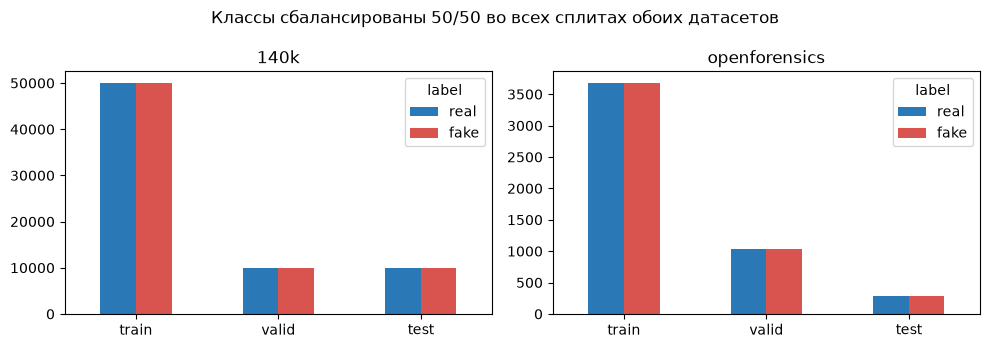

In [5]:
counts = index.groupby(["dataset", "split", "label"]).size().unstack("label").rename(columns={0: "real", 1: "fake"})
splits = ["train", "valid", "test"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, ds in zip(axes, ["140k", "openforensics"]):
    counts.loc[ds].loc[splits].plot.bar(ax=ax, color=COLORS, rot=0)
    ax.set_title(ds)
    ax.set_xlabel("")
fig.suptitle("Классы сбалансированы 50/50 во всех сплитах обоих датасетов")
fig.tight_layout()
counts

**Вывод:** real и fake поровну в каждом сплите. В 140k так в исходных данных, в OpenForensics так устроена подвыборка.

| сплит | 140k real / fake | OpenForensics real / fake |
|---|---|---|
| train | 50 000 / 50 000 | 3 678 / 3 678 |
| valid | 10 000 / 10 000 | 1 036 / 1 036 |
| test | 10 000 / 10 000 | 286 / 286 |

## 3. Метаданные

Для каждого файла индекса: формат, размер, режим, качество JPEG и его таблицы квантования, субдискретизация, progressive, EXIF, ICC, полное декодирование. Кэш – `data/processed/metadata.csv`.

Различие real и fake: для числовых полей ROC-AUC по одному полю: max(AUC, 1 − AUC) и класс с бо́льшими значениями (`higher`), для категориальных – доли значений и TVD (полусумма модулей разностей долей). Порог различия: max(AUC, 1 − AUC) − 0.5 ≥ 0.05 или TVD ≥ 0.05.

In [6]:
from src.metadata import build_metadata, compare_classes

meta = build_metadata()
name = meta["path"].str.rsplit("/", n=1).str[1].str.rsplit(".", n=1).str[0]
meta["name_len"] = name.str.len()
meta["name_is_digits"] = name.str.isdigit()

numeric = ["width", "height", "file_size", "quality", "quality_error"]
categorical = ["format", "mode", "qtable_hash", "subsampling", "progressive", "has_exif", "has_icc", "opens"]
fields = {
    "140k": (numeric + ["name_len"], categorical + ["name_is_digits"]),
    "openforensics": (numeric, categorical),
}
summary = {ds: compare_classes(meta[meta["dataset"] == ds], *fields[ds]) for ds in fields}

In [7]:
summary["140k"]

,field,n_unique,real,fake,differs,auc,higher,tvd
0,width,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
1,height,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
2,file_size,19698,"median 28725.0, [13803, 51686]","median 27991.0, [15752, 53525]",False,0.544,real,NaN
3,quality,1,"median 95.0, [95, 95]","median 95.0, [95, 95]",False,NaN,NaN,NaN
4,quality_error,1,"median 0.0, [0.0, 0.0]","median 0.0, [0.0, 0.0]",False,NaN,NaN,NaN
5,name_len,2,"median 5.0, [5, 5]","median 10.0, [10, 10]",True,1.000,fake,NaN
6,format,1,JPEG: 1.0,JPEG: 1.0,False,NaN,NaN,0.0
7,mode,1,RGB: 1.0,RGB: 1.0,False,NaN,NaN,0.0
8,qtable_hash,1,c73b79bf: 1.0,c73b79bf: 1.0,False,NaN,NaN,0.0
9,subsampling,1,4:2:0: 1.0,4:2:0: 1.0,False,NaN,NaN,0.0


In [8]:
summary["openforensics"]

,field,n_unique,real,fake,differs,auc,higher,tvd
0,width,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
1,height,1,"median 256.0, [256, 256]","median 256.0, [256, 256]",False,NaN,NaN,NaN
2,file_size,5962,"median 9088.0, [2117, 30790]","median 9544.5, [2285, 23788]",True,0.557,fake,NaN
3,quality,1,"median 75.0, [75, 75]","median 75.0, [75, 75]",False,NaN,NaN,NaN
4,quality_error,1,"median 0.0, [0.0, 0.0]","median 0.0, [0.0, 0.0]",False,NaN,NaN,NaN
5,format,1,JPEG: 1.0,JPEG: 1.0,False,NaN,NaN,0.0
6,mode,1,RGB: 1.0,RGB: 1.0,False,NaN,NaN,0.0
7,qtable_hash,1,0e368a84: 1.0,0e368a84: 1.0,False,NaN,NaN,0.0
8,subsampling,1,4:2:0: 1.0,4:2:0: 1.0,False,NaN,NaN,0.0
9,progressive,1,False: 1.0,False: 1.0,False,NaN,NaN,0.0


Графики – только для полей с различиями: имена файлов в 140k и размер файла в OpenForensics.

label,real,fake
name_len,,
5,70000,0
10,0,70000


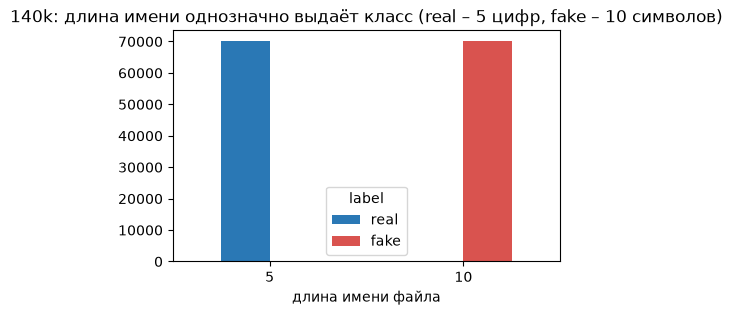

In [9]:
meta_140k = meta[meta["dataset"] == "140k"]
names = meta_140k.groupby(["name_len", "label"]).size().unstack("label", fill_value=0).rename(columns={0: "real", 1: "fake"})

ax = names.plot.bar(color=COLORS, rot=0, figsize=(5, 3))
ax.set_xlabel("длина имени файла")
ax.set_title("140k: длина имени однозначно выдаёт класс (real – 5 цифр, fake – 10 символов)")
names

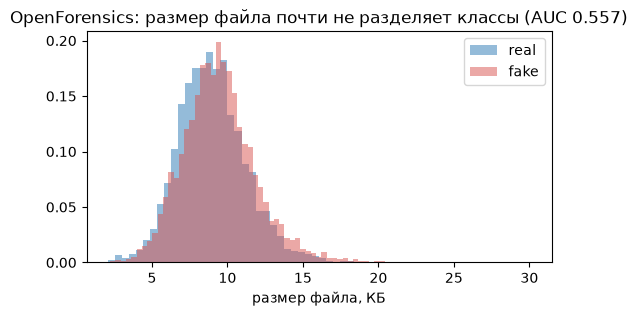

In [10]:
meta_of = meta[meta["dataset"] == "openforensics"]
auc = summary["openforensics"].set_index("field").loc["file_size", "auc"]

fig, ax = plt.subplots(figsize=(6, 3))
for label, cls in enumerate(["real", "fake"]):
    sizes = meta_of.loc[meta_of["label"] == label, "file_size"] / 1024
    ax.hist(sizes, bins=60, alpha=0.5, density=True, color=COLORS[cls], label=cls)
ax.set_xlabel("размер файла, КБ")
ax.legend()
ax.set_title(f"OpenForensics: размер файла почти не разделяет классы (AUC {auc})");

Проблемные файлы: не открываются, режим не RGB, размер отличается от самого частого в датасете.

In [11]:
common_size = meta.groupby("dataset")[["width", "height"]].agg(lambda s: s.mode()[0])
odd_size = (meta[["width", "height"]] != common_size.loc[meta["dataset"]].values).any(axis=1)
problems = meta[~meta["opens"] | (meta["mode"] != "RGB") | odd_size]

print("самый частый размер:", common_size.to_dict("index"))
print("проблемных файлов:", len(problems))
problems

самый частый размер: {'140k': {'width': 256, 'height': 256}, 'openforensics': {'width': 256, 'height': 256}}
проблемных файлов: 0


,path,dataset,split,label,format,width,height,mode,progressive,has_exif,has_icc,quality,quality_error,qtable_hash,subsampling,opens,file_size,name_len,name_is_digits


**Вывод:** технически файлы однородны. Все открываются, все JPEG RGB 256×256, без EXIF и ICC, baseline, субдискретизация 4:2:0, таблицы квантования стандартные (ошибка подгонки 0). В пределах датасета качество одинаковое у real и fake: 95 в 140k, 75 в OpenForensics. Размер файла различается слабо.

- Имена файлов выдают класс в обоих датасетах (140k: real – 5 цифр, fake – 10 символов; OpenForensics: префикс `real_*` / `fake_*`), поэтому в признаки и в детектор-читер их не включаем.
- Качество JPEG различается между датасетами (95 и 75): в кросс-датасетной проверке это нужно контролировать.

| показатель | 140k | OpenForensics |
|---|---|---|
| не открываются / не RGB / нестандартный размер | 0 / 0 / 0 | 0 / 0 / 0 |
| размер | 256×256 | 256×256 |
| качество JPEG (real = fake) | 95 | 75 |
| субдискретизация / progressive / EXIF / ICC | 4:2:0 / нет / нет / нет | 4:2:0 / нет / нет / нет |
| ROC-AUC размера файла, max(AUC, 1 − AUC) | 0.544 (real больше) | 0.557 (fake больше) |
| имя файла выдаёт класс | да (длина 5 vs 10) | да (префикс) |

## 4. Примеры

Случайные картинки train и средняя картинка по каждому классу.

In [12]:
import numpy as np
from PIL import Image

from src.config import SEED

train = index[index["split"] == "train"]
classes = {0: "real", 1: "fake"}
datasets = ["140k", "openforensics"]


def load(path, size=None):
    with Image.open(RAW_DIR / path) as im:
        return im.resize((size, size)) if size else im.convert("RGB")

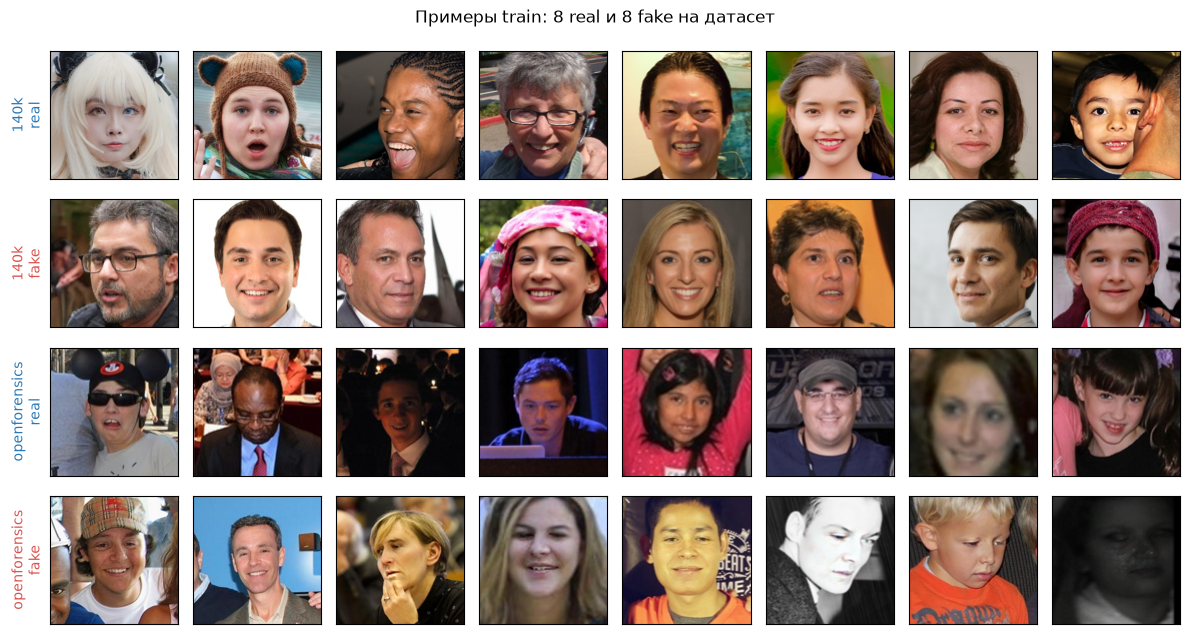

In [13]:
samples = train.groupby(["dataset", "label"]).sample(8, random_state=SEED)

fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for row, ((ds, label), group) in zip(axes, samples.groupby(["dataset", "label"])):
    for ax, path in zip(row, group["path"]):
        ax.imshow(load(path, 128))
        ax.set_xticks([])
        ax.set_yticks([])
    row[0].set_ylabel(f"{ds}\n{classes[label]}", color=COLORS[classes[label]])
fig.suptitle("Примеры train: 8 real и 8 fake на датасет")
fig.tight_layout()

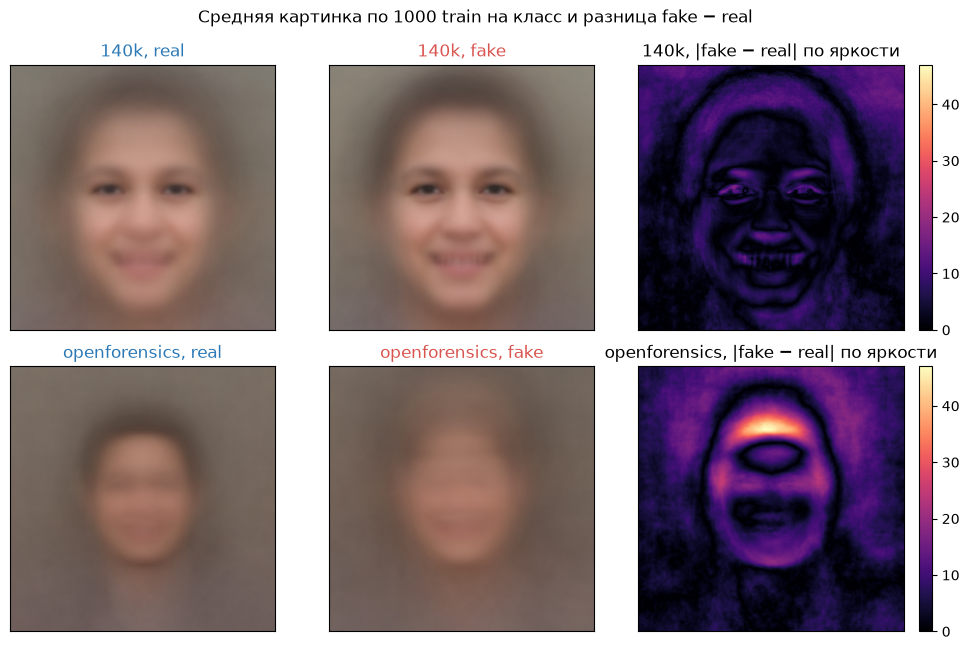

In [14]:
means = {
    key: np.mean([np.asarray(load(p), dtype=np.float32) for p in group["path"]], axis=0)
    for key, group in train.groupby(["dataset", "label"]).sample(1000, random_state=SEED).groupby(["dataset", "label"])
}
luma = np.array([0.299, 0.587, 0.114])
diffs = {ds: np.abs(means[(ds, 1)] @ luma - means[(ds, 0)] @ luma) for ds in datasets}
vmax = max(d.max() for d in diffs.values())

fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for row, ds in zip(axes, datasets):
    for ax, label in zip(row, classes):
        ax.imshow(means[(ds, label)].astype(np.uint8))
        ax.set_title(f"{ds}, {classes[label]}", color=COLORS[classes[label]])
    shown = row[2].imshow(diffs[ds], cmap="magma", vmin=0, vmax=vmax)
    row[2].set_title(f"{ds}, |fake − real| по яркости")
    fig.colorbar(shown, ax=row[2], fraction=0.046)
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Средняя картинка по 1000 train на класс и разница fake − real")
fig.tight_layout()

**Что видно:**
В 140k средние лица чёткие и совпадают по положению: лица выровнены одинаково, разница fake − real мала (≤16/255) и сосредоточена в чертах лица и яркости фона сверху. В OpenForensics средние размыты (положение лиц варьируется), разница до 45/255 с максимумом на лбу и линии волос: у fake лицо в кадре в среднем крупнее или сдвинуто. Это риск шортката по кадрированию – проверим количественно на шаге 5. Для сервиса нужен единый кроп и выравнивание лица.

## 5. Статистики лица

Выборка: 140k – по 5000 real и fake из train+valid, OpenForensics – все train+valid индекса. Лица и 478 точек – MediaPipe FaceLandmarker, при нескольких лицах берём самое крупное. Yaw и roll – из матрицы поворота головы, яркость – L в LAB (0–100). Сравнение real и fake – KS-тест.

Рамка лица строится по точкам лица и не включает верх лба и волосы.

In [15]:
from src.face_stats import FIELDS, build_face_stats, ks_table

face = build_face_stats()
continuous = [f for f in FIELDS if f != "n_faces"]
face.groupby(["dataset", "label"]).size()

dataset        label
140k           0        5000
               1        5000
openforensics  0        4714
               1        4714
dtype: int64

Число найденных лиц: доли значений по классам.

In [16]:
n_faces = face.groupby(["dataset", "label"])["n_faces"].value_counts(normalize=True).unstack(fill_value=0)
n_faces[">=2"] = n_faces.loc[:, n_faces.columns > 1].sum(axis=1)
n_faces.rename(index=classes, level="label").round(4)

n_faces                   0       1       2       3       4       5     >=2
dataset       label                                                        
140k          real   0.0006  0.9916  0.0076  0.0002  0.0000  0.0000  0.0078
              fake   0.0000  0.9998  0.0002  0.0000  0.0000  0.0000  0.0002
openforensics real   0.0187  0.8146  0.1411  0.0221  0.0032  0.0004  0.1667
              fake   0.0174  0.8946  0.0829  0.0047  0.0004  0.0000  0.0880

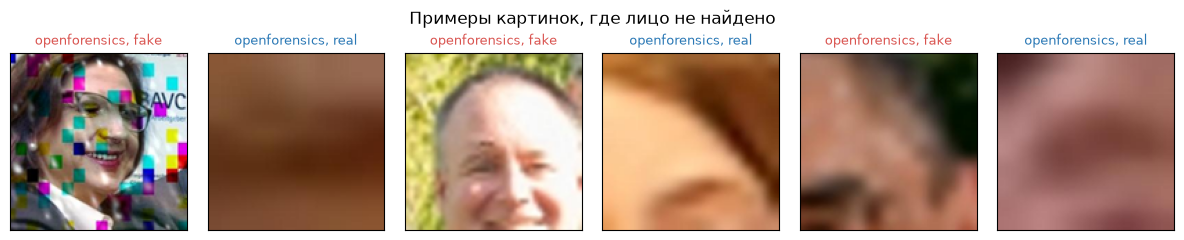

In [17]:
no_face = face[face["n_faces"] == 0]
examples = no_face.sample(min(6, len(no_face)), random_state=SEED)

fig, axes = plt.subplots(1, len(examples), figsize=(2 * len(examples), 2.4))
for ax, (_, row) in zip(axes, examples.iterrows()):
    ax.imshow(load(row["path"], 128))
    ax.set_title(f"{row['dataset']}, {classes[row['label']]}", fontsize=9, color=COLORS[classes[row["label"]]])
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Примеры картинок, где лицо не найдено")
fig.tight_layout()

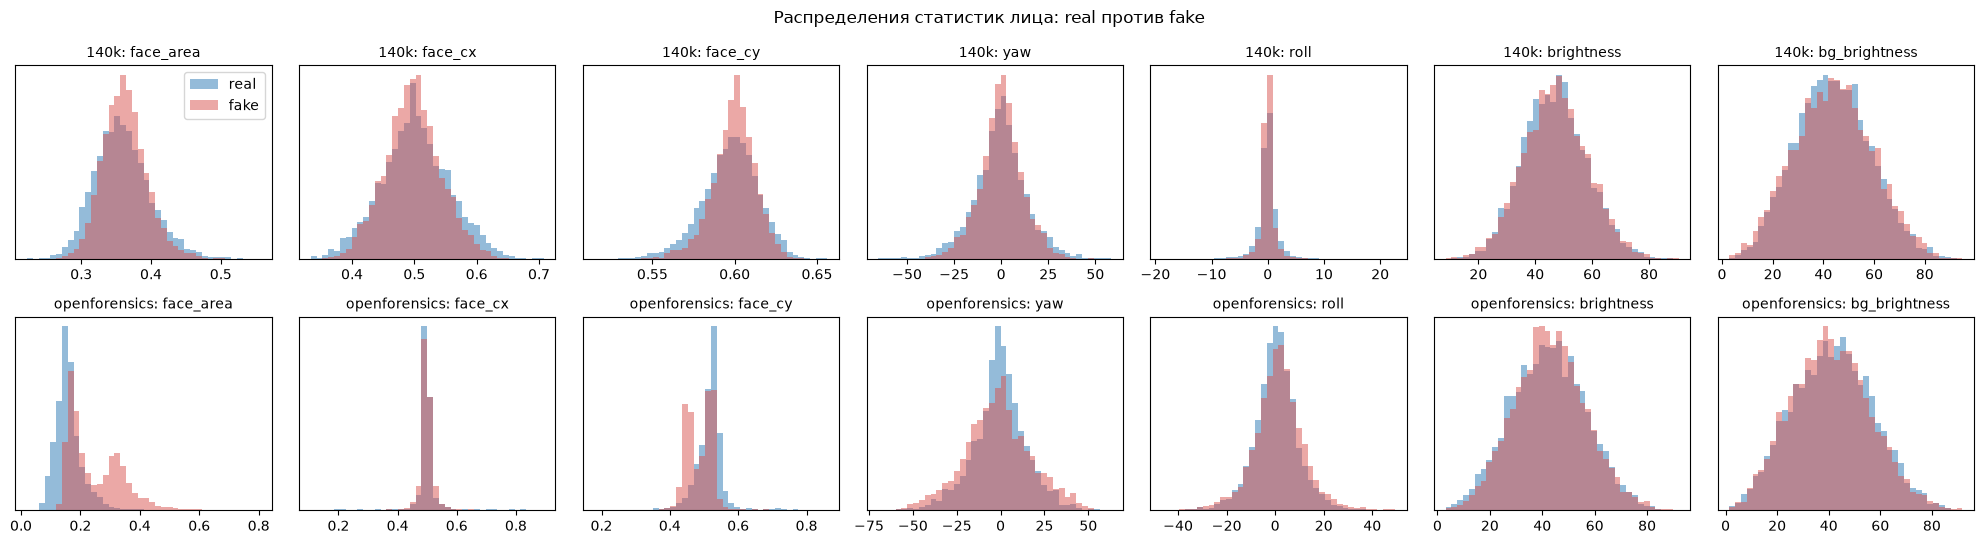

In [18]:
fig, axes = plt.subplots(2, len(continuous), figsize=(20, 5.5))
for row, ds in zip(axes, datasets):
    group = face[face["dataset"] == ds]
    for ax, field in zip(row, continuous):
        values = group[field].dropna()
        bins = np.histogram_bin_edges(values, bins=40)
        for label, cls in classes.items():
            ax.hist(group.loc[group["label"] == label, field].dropna(), bins=bins, density=True, alpha=0.5, color=COLORS[cls], label=cls)
        ax.set_title(f"{ds}: {field}", fontsize=10)
        ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Распределения статистик лица: real против fake")
fig.tight_layout()

In [19]:
ks = ks_table(face, continuous)
ks

,dataset,field,ks_d,p_value,n_real,n_fake
0,140k,face_area,0.100,3.229990e-22,4997,5000
1,140k,face_cx,0.071,2.499122e-11,4997,5000
2,140k,face_cy,0.105,1.253251e-24,4997,5000
3,140k,yaw,0.054,9.070642e-07,4997,5000
4,140k,roll,0.099,5.872313e-22,4997,5000
5,140k,brightness,0.021,2.111523e-01,5000,5000
6,140k,bg_brightness,0.021,2.015901e-01,4997,5000
7,openforensics,face_area,0.463,0.000000e+00,4626,4632
8,openforensics,face_cx,0.072,7.721126e-11,4626,4632
9,openforensics,face_cy,0.308,7.085028e-195,4626,4632


Отношение std fake / std real: больше 1 – у fake разброс шире.

In [20]:
std = face.groupby(["dataset", "label"])[continuous].std()
(std.xs(1, level="label") / std.xs(0, level="label")).T.round(3)

dataset,140k,openforensics
face_area,0.773,1.698
face_cx,0.812,0.700
face_cy,0.765,0.864
yaw,0.802,1.253
roll,0.611,1.159
brightness,1.018,0.957
bg_brightness,1.056,0.982


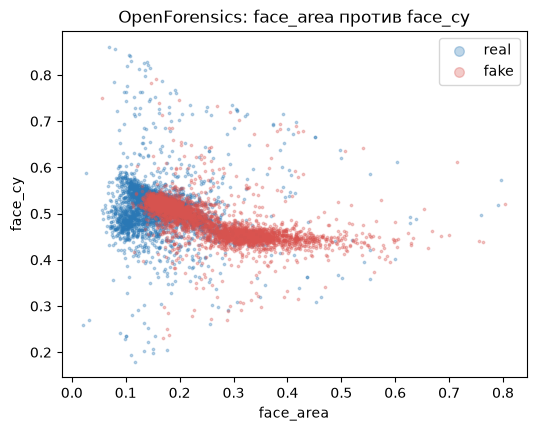

In [21]:
of = face[face["dataset"] == "openforensics"]

fig, ax = plt.subplots(figsize=(6, 4.5))
for label, cls in classes.items():
    group = of[of["label"] == label]
    ax.scatter(group["face_area"], group["face_cy"], s=3, alpha=0.3, color=COLORS[cls], label=cls)
ax.set_xlabel("face_area")
ax.set_ylabel("face_cy")
ax.legend(markerscale=4)
ax.set_title("OpenForensics: face_area против face_cy");

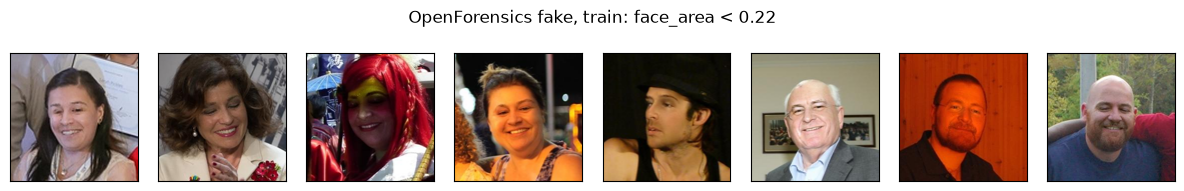

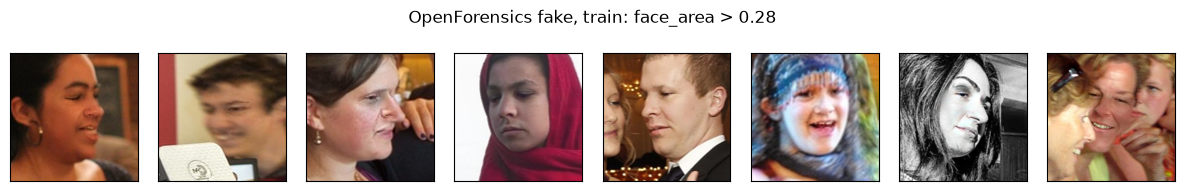

In [22]:
of_fake_train = of[(of["label"] == 1) & (of["split"] == "train")]
for name, mask in [("face_area < 0.22", of_fake_train["face_area"] < 0.22), ("face_area > 0.28", of_fake_train["face_area"] > 0.28)]:
    fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
    for ax, path in zip(axes, of_fake_train[mask].sample(8, random_state=SEED)["path"]):
        ax.imshow(load(path, 128))
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"OpenForensics fake, train: {name}")
    fig.tight_layout()

**Что видно:**

| показатель | 140k | OpenForensics |
|---|---|---|
| лицо не найдено, real / fake | 0.06% / 0.00% | 1.87% / 1.74% |
| 2 и более лиц, real / fake | 0.78% / 0.02% | 16.67% / 8.80% |
| KS D face_area | 0.100 | 0.463 |
| KS D face_cx | 0.071 | 0.072 |
| KS D face_cy | 0.105 | 0.308 |
| KS D yaw | 0.054 | 0.100 |
| KS D roll | 0.099 | 0.069 |
| KS D brightness (p) | 0.021 (0.21) | 0.039 (0.0014) |
| KS D bg_brightness (p) | 0.021 (0.20) | 0.035 (0.0067) |

Для остальных величин p < 1e-6.

## 6. Детектор-читер

Можно ли отличить real от fake по признакам, не связанным с самой подделкой. Выборка – как в разделе 5, без картинок, где лицо не найдено. Группы признаков: метаданные (размер файла), лицо (площадь, центр, yaw, roll, число лиц), картинка (яркость, яркость фона, резкость – дисперсия лапласиана по L, chroma – среднее sqrt(a² + b²) в LAB, is_gray – chroma < 3, порог предварительный). Модели – логрегрессия со стандартизацией и HistGradientBoosting, обучение на train, ROC-AUC на valid.

In [23]:
from src.cheater import FEATURE_GROUPS, cheater_auc, cheater_data, cheater_importance, feature_auc

cheat = cheater_data()
print("пропусков в признаках:", cheat[FEATURE_GROUPS["all"]].isna().sum().sum())
cheat.groupby(["dataset", "split", "label"]).size().unstack("label").rename(columns=classes)

пропусков в признаках: 0


label                real  fake
dataset       split            
140k          train  4194  4145
              valid   803   855
openforensics train  3607  3621
              valid  1019  1011

Резкость и chroma: real против fake.

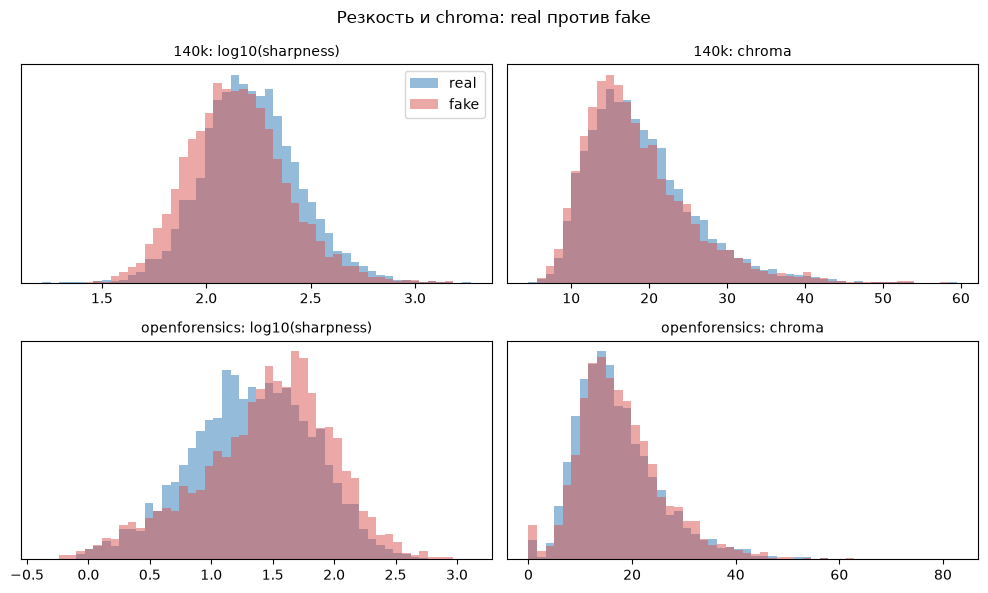

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for row, ds in zip(axes, datasets):
    group = cheat[cheat["dataset"] == ds]
    for ax, field, values in [
        (row[0], "log10(sharpness)", np.log10(group["sharpness"])),
        (row[1], "chroma", group["chroma"]),
    ]:
        bins = np.histogram_bin_edges(values, bins=50)
        for label, cls in classes.items():
            ax.hist(values[group["label"] == label], bins=bins, density=True, alpha=0.5, color=COLORS[cls], label=cls)
        ax.set_title(f"{ds}: {field}", fontsize=10)
        ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Резкость и chroma: real против fake")
fig.tight_layout()

In [25]:
ks_table(cheat, ["sharpness", "chroma"])

,dataset,field,ks_d,p_value,n_real,n_fake
0,140k,sharpness,0.123,1.239470e-33,4997,5000
1,140k,chroma,0.055,4.263689e-07,4997,5000
2,openforensics,sharpness,0.134,1.715137e-36,4626,4632
3,openforensics,chroma,0.055,1.289554e-06,4626,4632


In [26]:
cheat.groupby(["dataset", "label"])["is_gray"].mean().unstack("label").rename(columns=classes).round(4)

label,real,fake
dataset,,
140k,0.0000,0.0000
openforensics,0.0106,0.0207


Проверка порога is_gray глазами: картинки с chroma < 3 и чуть выше порога (3–6).

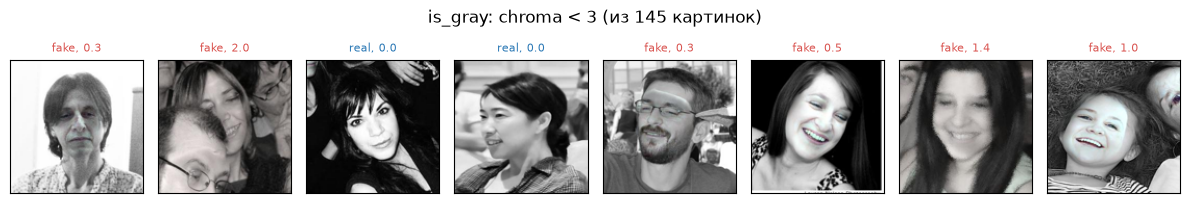

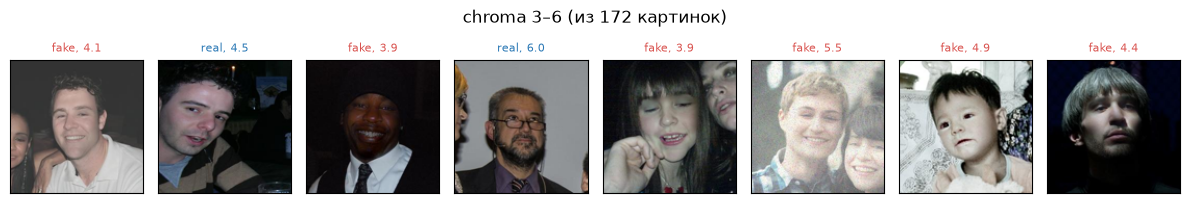

In [27]:
for name, mask in [("is_gray: chroma < 3", cheat["chroma"] < 3), ("chroma 3–6", cheat["chroma"].between(3, 6))]:
    group = cheat[mask].sample(min(8, mask.sum()), random_state=SEED)
    fig, axes = plt.subplots(1, 8, figsize=(12, 2.1))
    for ax, (_, row) in zip(axes, group.iterrows()):
        ax.imshow(load(row["path"], 128))
        ax.set_title(f"{classes[row['label']]}, {row['chroma']:.1f}", fontsize=8, color=COLORS[classes[row["label"]]])
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{name} (из {mask.sum()} картинок)")
    fig.tight_layout()

ROC-AUC на valid: датасет × группа признаков × модель.

In [28]:
auc = cheater_auc(cheat)
auc.pivot_table(index=["dataset", "group"], columns="model", values="auc").loc[:, ["logreg", "boosting"]]

model                   logreg  boosting
dataset       group                     
140k          all        0.635     0.730
              face       0.600     0.725
              image      0.597     0.587
              metadata   0.545     0.528
openforensics all        0.839     0.869
              face       0.807     0.824
              image      0.704     0.663
              metadata   0.652     0.559

Каждый признак отдельно на valid: max(AUC, 1 − AUC) и класс с бо́льшими значениями.

In [29]:
feature_auc(cheat).pivot(index="feature", columns="dataset", values=["auc", "higher"]).loc[FEATURE_GROUPS["all"]]

auc               higher              
dataset         140k openforensics   140k openforensics
feature                                                
file_size      0.545         0.652   real          fake
face_area      0.549          0.81   fake          fake
face_cx         0.51         0.503   real          fake
face_cy        0.545         0.692   fake          real
yaw              0.5         0.547   fake          real
roll           0.527         0.545   real          fake
n_faces        0.503         0.505   real          real
brightness     0.513         0.555   fake          fake
bg_brightness  0.511         0.525   fake          fake
sharpness      0.593         0.685   real          fake
chroma         0.543         0.518   real          real
is_gray          NaN         0.518    NaN          fake

Permutation importance бустинга на всех признаках (valid, падение ROC-AUC, 10 повторов).

In [30]:
pd.concat({ds: cheater_importance(cheat, ds) for ds in datasets}, axis=1)

140k         openforensics        
                 mean     std          mean     std
face_cx        0.1025  0.0062        0.0161  0.0043
roll           0.0822  0.0090        0.0024  0.0016
yaw            0.0680  0.0044        0.0106  0.0034
sharpness      0.0625  0.0046        0.0818  0.0060
face_cy        0.0434  0.0045        0.0151  0.0029
face_area      0.0369  0.0057        0.3025  0.0098
file_size      0.0313  0.0053        0.0047  0.0024
chroma         0.0148  0.0030        0.0016  0.0007
brightness     0.0100  0.0039        0.0033  0.0012
bg_brightness  0.0051  0.0025        0.0022  0.0008
n_faces        0.0026  0.0017        0.0006  0.0002
is_gray        0.0000  0.0000        0.0046  0.0013

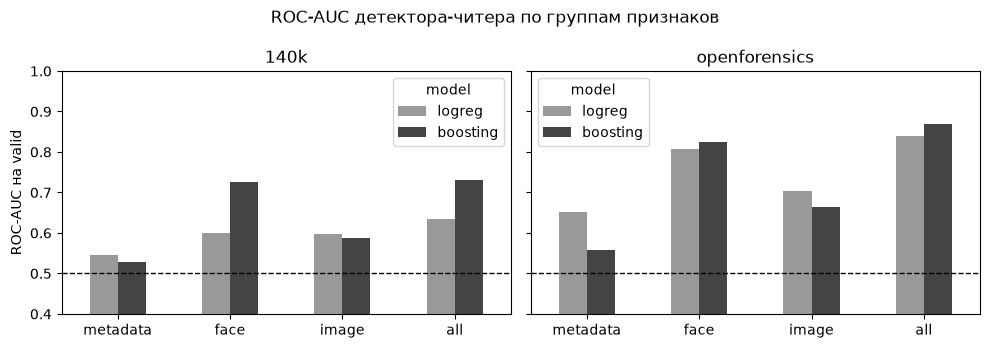

In [31]:
groups = list(FEATURE_GROUPS)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, ds in zip(axes, datasets):
    table = auc[auc["dataset"] == ds].pivot(index="group", columns="model", values="auc").loc[groups, ["logreg", "boosting"]]
    table.plot.bar(ax=ax, rot=0, color=["#999999", "#444444"])
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
    ax.set_ylim(0.4, 1)
    ax.set_title(ds)
    ax.set_xlabel("")
axes[0].set_ylabel("ROC-AUC на valid")
fig.suptitle("ROC-AUC детектора-читера по группам признаков")
fig.tight_layout()

Допроверка 1: ловит ли бустинг разброс. Признаки отклонения: |face_cx − 0.5|, |face_cy − медиана face_cy по train датасета|, |yaw|, |roll|. Логрегрессия на группе «лицо» без них и с ними.

In [32]:
from src.cheater import DEVIATION_FEATURES, MODELS, add_deviations

cheat_dev = add_deviations(cheat)
face_groups = {"face": FEATURE_GROUPS["face"], "face + отклонения": FEATURE_GROUPS["face"] + DEVIATION_FEATURES}
dev_auc = cheater_auc(cheat_dev, face_groups, {"logreg": MODELS["logreg"]})
boosting_face = auc[(auc["group"] == "face") & (auc["model"] == "boosting")].set_index("dataset")["auc"].rename("boosting, face")
dev_auc.pivot(index="dataset", columns="group", values="auc").join(boosting_face)

,face,face + отклонения,"boosting, face"
dataset,,,
140k,0.600,0.677,0.725
openforensics,0.807,0.804,0.824


Допроверка 2: OpenForensics, размер файла – AUC отдельно на train и valid, KS D между train и valid внутри класса.

In [33]:
from scipy.stats import ks_2samp

of_cheat = cheat[cheat["dataset"] == "openforensics"]
rows = []
for split in ["train", "valid"]:
    part = of_cheat[of_cheat["split"] == split]
    a = roc_auc_score(part["label"], part["file_size"])
    rows.append({"split": split, "auc": round(max(a, 1 - a), 3), "higher": "fake" if a > 0.5 else "real"})
display(pd.DataFrame(rows))

rows = []
for label, cls in classes.items():
    part = of_cheat[of_cheat["label"] == label]
    ks = ks_2samp(part.loc[part["split"] == "train", "file_size"], part.loc[part["split"] == "valid", "file_size"])
    rows.append({"class": cls, "ks_d train vs valid": round(ks.statistic, 3), "p_value": ks.pvalue})
pd.DataFrame(rows)

,split,auc,higher
0,train,0.529,fake
1,valid,0.652,fake


,class,ks_d train vs valid,p_value
0,real,0.036,2.353457e-01
1,fake,0.221,2.160435e-34


Допроверка 3: число is_gray по классам и сплитам.

In [34]:
cheat[cheat["is_gray"] == 1].groupby(["dataset", "split", "label"]).size().unstack("label", fill_value=0).rename(columns=classes)

label                real  fake
dataset       split            
openforensics train    33    43
              valid    16    53

Допроверка 4: резкость в рамке лица и вне её (фон), real против fake. Направление – класс с бо́льшей медианой.

In [35]:
sharp_fields = ["sharpness", "face_sharpness", "bg_sharpness"]
sharp_ks = ks_table(cheat, sharp_fields)
medians = cheat.groupby(["dataset", "label"])[sharp_fields].median()
sharp_ks["higher"] = [
    "fake" if medians.loc[(ds, 1), f] > medians.loc[(ds, 0), f] else "real"
    for ds, f in zip(sharp_ks["dataset"], sharp_ks["field"])
]
sharp_ks

,dataset,field,ks_d,p_value,n_real,n_fake,higher
0,140k,sharpness,0.123,1.239470e-33,4997,5000,real
1,140k,face_sharpness,0.131,1.215875e-37,4997,5000,real
2,140k,bg_sharpness,0.109,2.751752e-26,4997,5000,real
3,openforensics,sharpness,0.134,1.715137e-36,4626,4632,fake
4,openforensics,face_sharpness,0.152,4.876065e-47,4626,4632,fake
5,openforensics,bg_sharpness,0.129,3.302790e-34,4626,4632,fake


Допроверка 5: OpenForensics, только fake – KS D между train и valid по face_area и резкости.

In [36]:
of_fake = cheat[(cheat["dataset"] == "openforensics") & (cheat["label"] == 1)]
rows = []
for field in ["face_area", "sharpness", "face_sharpness", "bg_sharpness"]:
    train_values = of_fake.loc[of_fake["split"] == "train", field].dropna()
    valid_values = of_fake.loc[of_fake["split"] == "valid", field].dropna()
    ks = ks_2samp(train_values, valid_values)
    rows.append({
        "field": field, "ks_d train vs valid": round(ks.statistic, 3), "p_value": ks.pvalue,
        "median train": round(train_values.median(), 3), "median valid": round(valid_values.median(), 3),
    })
pd.DataFrame(rows)

,field,ks_d train vs valid,p_value,median train,median valid
0,face_area,0.160,3.246341e-18,0.222,0.209
1,sharpness,0.255,1.515557e-45,27.642,53.812
2,face_sharpness,0.242,5.382845e-41,24.943,43.251
3,bg_sharpness,0.253,4.226304e-45,27.446,55.592


**Что видно:**

| ROC-AUC на valid (logreg / boosting) | 140k | OpenForensics |
|---|---|---|
| метаданные | 0.545 / 0.528 | 0.652 / 0.559 |
| лицо | 0.600 / 0.725 | 0.807 / 0.824 |
| картинка | 0.597 / 0.587 | 0.704 / 0.663 |
| все признаки | 0.635 / 0.730 | 0.839 / 0.869 |
| топ-3 permutation importance (boosting, все) | face_cx, roll, yaw | face_area, sharpness, face_cx |
| лучший одиночный признак, max(AUC, 1 − AUC) | sharpness 0.593 (real больше) | face_area 0.81 (fake больше) |
| KS D sharpness / chroma | 0.123 / 0.055 | 0.134 / 0.055 |
| доля is_gray, real / fake | 0.0000 / 0.0000 | 0.0106 / 0.0207 |